# Video — Tracking Objek (YOLOv8n + ByteTrack)
**Kapan dipakai:** menghitung orang/kendaraan yang melewati garis, jumlah dan lama berada di
zona, jalur gerak (heatmap), atau membuat video beranotasi.

**Idenya:** YOLO mendeteksi kotak objek tiap frame, tracker memberi tiap objek satu **ID**
yang sama dari frame ke frame. Hasilnya tabel `tracks` (frame, id, posisi). Semua hitungan
diturunkan dari tabel itu, jadi deteksi cukup dijalankan sekali.

**Langkah:**
1. Deteksi + tracking tiap frame → tabel `tracks`.
2. Hitung: lewat garis, isi zona, lama di zona, heatmap.
3. Simpan tabel, heatmap, dan video beranotasi.

**Data demo:** `vtest.avi` dari OpenCV (pejalan kaki, 768x576, 10 fps, 795 frame).
Koordinat piksel: x ke kanan, y ke bawah.

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from ultralytics import YOLO

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/video/vtest"   # GANTI saat lomba
VIDEO_PATH = f"{DATA_FOLDER}/vtest.avi"
WEIGHTS = "Z:/GEMASTIK-DATABASE/pretrained/yolov8n/yolov8n.pt"

CLASSES = [0]             # id kelas COCO: 0 = orang, 2 = mobil, 3 = motor, 5 = bus
CONFIDENCE = 0.3
TRACKER = "bytetrack.yaml"
# TRACKER = "botsort.yaml"        # lebih tahan saat objek saling menutupi
LINE_START = (430, 0)     # garis hitung: titik awal dan titik akhir
LINE_END = (430, 576)
ZONE = [(560, 230), (768, 250), (768, 420), (560, 400)]   # poligon zona, urut keliling
MIN_AREA = 300            # background subtraction: luas minimum gumpalan gerak
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = 0

## Info video + satu frame dengan garis dan zona

fps: 10.0 | ukuran: 768 x 576


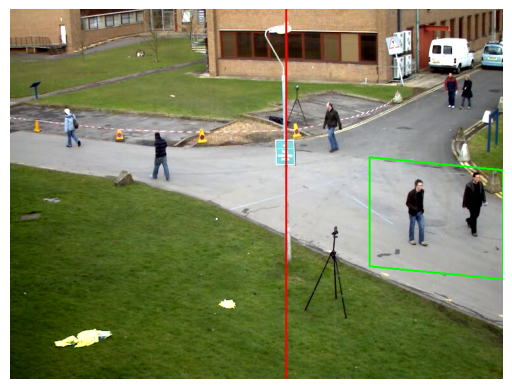

In [3]:
video = cv2.VideoCapture(VIDEO_PATH)
FPS = video.get(cv2.CAP_PROP_FPS)
WIDTH = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
HEIGHT = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))
print("fps:", FPS, "| ukuran:", WIDTH, "x", HEIGHT)

video.set(cv2.CAP_PROP_POS_FRAMES, 200)
ok, frame = video.read()
zone_polygon = np.array(ZONE, dtype=np.int32)
cv2.line(frame, LINE_START, LINE_END, (0, 0, 255), 2)
cv2.polylines(frame, [zone_polygon], True, (0, 255, 0), 2)
plt.imshow(frame[:, :, ::-1])               # BGR (OpenCV) → RGB
plt.axis("off")
plt.show()

## Langkah 1 — deteksi + tracking → tabel `tracks`
Posisi = **titik kaki** (tengah sisi bawah kotak), cocok untuk garis dan zona di lantai.

In [4]:
model = YOLO(WEIGHTS)
video = cv2.VideoCapture(VIDEO_PATH)
rows = []
frame_number = 0
ok, frame = video.read()
while ok:
    results = model.track(frame, persist=True, tracker=TRACKER, classes=CLASSES,
                          conf=CONFIDENCE, device=DEVICE, verbose=False)
    boxes = results[0].boxes
    if boxes.id is not None:
        corners = boxes.xyxy.cpu().numpy()
        object_ids = boxes.id.cpu().numpy()
        for i in range(len(object_ids)):
            x1, y1, x2, y2 = corners[i]
            rows.append([frame_number, int(object_ids[i]), x1, y1, x2, y2, (x1 + x2) / 2, y2])
    frame_number += 1
    ok, frame = video.read()

tracks = pd.DataFrame(rows, columns=["frame", "id", "x1", "y1", "x2", "y2", "foot_x", "foot_y"])
print(tracks.shape, "| jumlah ID:", tracks["id"].nunique())
tracks.head()

WARNING NMS time limit 2.050s exceeded


(4581, 8) | jumlah ID: 44


,frame,id,x1,y1,x2,y2,foot_x,foot_y
0,0,1,640.394958,240.381622,683.858948,322.748749,662.126953,322.748749
1,0,2,253.483032,219.075012,282.287170,308.759338,267.885101,308.759338
2,0,3,499.271515,156.856537,530.200134,231.521149,514.735840,231.521149
3,1,1,637.137268,241.458466,680.341980,323.164825,658.739624,323.164825
4,1,2,263.141541,219.589478,291.761139,307.667572,277.451355,307.667572


## Langkah 2a — lama tiap ID terlihat

In [5]:
per_id = tracks.groupby("id")
summary = pd.DataFrame()
summary["first_frame"] = per_id["frame"].min()
summary["last_frame"] = per_id["frame"].max()
summary["seconds"] = per_id["frame"].count() / FPS
print(summary["seconds"].describe())
summary.sort_values("seconds", ascending=False).head(10)

count    44.000000
mean     10.411364
std      10.727127
min       0.100000
25%       1.175000
50%       8.600000
75%      15.625000
max      36.100000
Name: seconds, dtype: float64


,first_frame,last_frame,seconds
id,,,
6,12,374,36.1
20,41,394,34.6
9,18,364,34.4
89,405,736,32.1
96,499,794,27.8
112,531,794,25.7
13,24,303,25.6
98,504,691,18.5
65,227,403,17.5


## Langkah 2b — objek yang melewati garis
`side` = di sisi mana titik kaki terhadap garis (positif atau negatif). Tanda berubah antar
frame = objek menyeberang.

In [6]:
tracks = tracks.sort_values(["id", "frame"])
line_dx = LINE_END[0] - LINE_START[0]
line_dy = LINE_END[1] - LINE_START[1]
tracks["side"] = (line_dx * (tracks["foot_y"] - LINE_START[1])
                  - line_dy * (tracks["foot_x"] - LINE_START[0]))

crossing_rows = []
for object_id, path in tracks.groupby("id"):
    sides = path["side"].to_numpy()
    frames = path["frame"].to_numpy()
    for i in range(1, len(sides)):
        if sides[i - 1] < 0 and sides[i] >= 0:
            crossing_rows.append([object_id, "negatif ke positif", frames[i]])
        if sides[i - 1] >= 0 and sides[i] < 0:
            crossing_rows.append([object_id, "positif ke negatif", frames[i]])
crossings = pd.DataFrame(crossing_rows, columns=["id", "direction", "frame"])
print("total menyeberang:", len(crossings), "| objek berbeda:", crossings["id"].nunique())
print(crossings["direction"].value_counts())

total menyeberang: 25 | objek berbeda: 19
direction
negatif ke positif    13
positif ke negatif    12
Name: count, dtype: int64


## Langkah 2c — isi zona + lama berada di zona (dwell time)

In [7]:
in_zone = []
for foot_x, foot_y in zip(tracks["foot_x"], tracks["foot_y"]):
    distance = cv2.pointPolygonTest(zone_polygon, (float(foot_x), float(foot_y)), False)
    in_zone.append(distance >= 0)
tracks["in_zone"] = in_zone

zone_tracks = tracks[tracks["in_zone"]]
dwell_seconds = zone_tracks.groupby("id").size() / FPS
people_per_frame = zone_tracks.groupby("frame").size()
print("objek yang pernah masuk zona:", len(dwell_seconds))
print("lama di zona (detik):")
print(dwell_seconds.describe())
print("isi zona terpadat:", people_per_frame.max())

objek yang pernah masuk zona: 24
lama di zona (detik):
count    24.00000
mean      4.31250
std       3.42755
min       0.10000
25%       2.12500
50%       3.20000
75%       6.62500
max      10.80000
dtype: float64
isi zona terpadat: 4


## Langkah 2d — heatmap posisi + jalur tiap ID

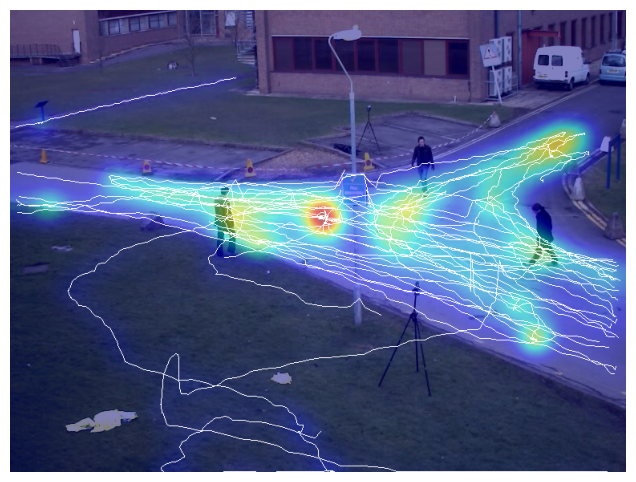

In [8]:
heat = np.zeros((HEIGHT, WIDTH), dtype=np.float32)
for foot_x, foot_y in zip(tracks["foot_x"], tracks["foot_y"]):
    heat[min(int(foot_y), HEIGHT - 1), min(int(foot_x), WIDTH - 1)] += 1
heat = cv2.GaussianBlur(heat, (0, 0), 15)
heat = (255 * heat / heat.max()).astype(np.uint8)
heat_colors = cv2.applyColorMap(heat, cv2.COLORMAP_JET)

video = cv2.VideoCapture(VIDEO_PATH)
ok, first_frame = video.read()
heatmap = cv2.addWeighted(first_frame, 0.5, heat_colors, 0.5, 0)
for object_id, path in tracks.groupby("id"):
    points = path[["foot_x", "foot_y"]].to_numpy()
    cv2.polylines(heatmap, [points.astype(np.int32)], False, (255, 255, 255), 1)
cv2.imwrite("heatmap.jpg", heatmap)
plt.figure(figsize=(8, 6))
plt.imshow(heatmap[:, :, ::-1])
plt.axis("off")
plt.show()

## Langkah 3a — video beranotasi (kotak + ID + garis + zona + penghitung)

In [9]:
writer = cv2.VideoWriter("anotasi.mp4", cv2.VideoWriter_fourcc(*"mp4v"), FPS, (WIDTH, HEIGHT))
video = cv2.VideoCapture(VIDEO_PATH)
frame_number = 0
ok, frame = video.read()
while ok:
    cv2.line(frame, LINE_START, LINE_END, (0, 0, 255), 2)
    cv2.polylines(frame, [zone_polygon], True, (0, 255, 0), 2)
    in_frame = tracks[tracks["frame"] == frame_number]
    for row in in_frame.itertuples():
        top_left = (int(row.x1), int(row.y1))
        cv2.rectangle(frame, top_left, (int(row.x2), int(row.y2)), (255, 128, 0), 2)
        cv2.putText(frame, f"ID {row.id}", (int(row.x1), int(row.y1) - 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 128, 0), 2)
    crossed = (crossings["frame"] <= frame_number).sum()      # hitungan sampai frame ini
    cv2.putText(frame, f"menyeberang: {crossed}", (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.7,
                (0, 0, 255), 2)
    writer.write(frame)
    frame_number += 1
    ok, frame = video.read()
writer.release()
print("video tersimpan: anotasi.mp4")

video tersimpan: anotasi.mp4


## Langkah 3b — simpan tabel lintasan

In [10]:
submission = pd.DataFrame()
submission["frame"] = tracks["frame"]
submission["id"] = tracks["id"]
submission["foot_x"] = tracks["foot_x"]
submission["foot_y"] = tracks["foot_y"]
submission["in_zone"] = tracks["in_zone"]
submission.to_csv("submission.csv", index=False)
submission.head()

,frame,id,foot_x,foot_y,in_zone
0,0,1,662.126953,322.748749,True
3,1,1,658.739624,323.164825,True
6,2,1,654.249023,324.259460,True
9,3,1,638.306458,323.939697,True
12,4,1,624.885986,324.235016,True


## Alternatif tanpa model: background subtraction (MOG2)
Menghitung gumpalan yang bergerak. Cepat dan tanpa GPU, tetapi tidak tahu jenis objek dan
tidak memberi ID.

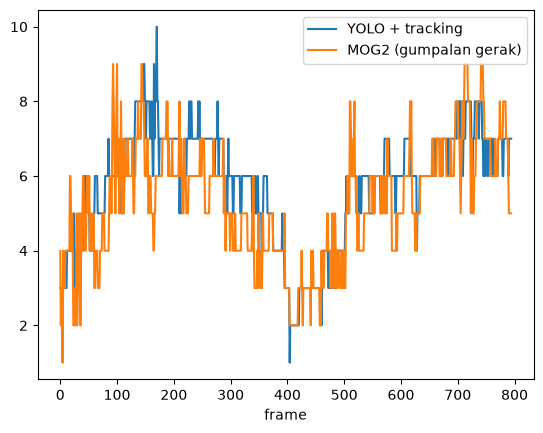

korelasi jumlah per frame: 0.765


In [11]:
subtractor = cv2.createBackgroundSubtractorMOG2(history=200, varThreshold=25, detectShadows=True)
moving_counts = []
video = cv2.VideoCapture(VIDEO_PATH)
ok, frame = video.read()
while ok:
    mask = subtractor.apply(frame)
    mask = cv2.threshold(mask, 200, 255, cv2.THRESH_BINARY)[1]     # 127 = bayangan, dibuang
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    mask = cv2.dilate(mask, np.ones((9, 9), np.uint8))
    contours = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0]
    count = 0
    for contour in contours:
        if cv2.contourArea(contour) > MIN_AREA:
            count += 1
    moving_counts.append(count)
    ok, frame = video.read()

yolo_counts = tracks.groupby("frame").size()
yolo_counts = yolo_counts.reindex(range(len(moving_counts)))
yolo_counts = yolo_counts.fillna(0)
plt.plot(yolo_counts.to_numpy(), label="YOLO + tracking")
plt.plot(moving_counts, label="MOG2 (gumpalan gerak)")
plt.xlabel("frame")
plt.legend()
plt.show()
print("korelasi jumlah per frame:", round(np.corrcoef(yolo_counts, moving_counts)[0, 1], 3))